# 04 · End-to-end evaluation (Member 4: chatbot)

The whole chatbot, through its real API (`POST /api/m4/chat` on the full SoilMind app), on the 60-question set
in `../eval/qa_testset.xlsx`: 30 English + 30 Sinhala, including 10 questions it must refuse and 10 that need the
field's live data.

**That spreadsheet is the only file the team reviews.** It was drafted by the AI coding assistant; until every row
is marked `checked - …`, these results are labelled **UNCHECKED**. After the review:
`python -m member4_chatbot.eval.import_testset` (or set `RUN_EVAL = True` below) and re-run this notebook.

Measures: intent accuracy, retrieval hit@3, answer correctness (key facts / live values present), citation
correctness, refusal precision and recall, hallucinated-number rate, latency on CPU.

`RUN_EVAL = True` imports the spreadsheet and runs every question (about 2 minutes, needs MongoDB and the trained
models). `False` only shows the last saved results in `../eval/results/`.

In [1]:
RUN_EVAL = True

In [2]:
import sys, json
from pathlib import Path
HERE = Path.cwd()
M4 = HERE.parent
sys.path.insert(0, str(M4))
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140)
RESULTS = M4 / "eval" / "results"
if RUN_EVAL:
    from member4_chatbot.eval import import_testset, run_eval
    import_testset.main([])
    run_eval.main([])
metrics = json.loads((RESULTS / "metrics.json").read_text(encoding="utf-8"))
res = pd.read_csv(RESULTS / "results.csv", keep_default_na=False)
print("generated:", metrics["generated_at"])

60 questions -> qa_testset.csv (0 removed); human-checked: 0 of 60
expected_behaviour  answer  live  refuse
lang                                    
en                      20     5       5
si                      20     5       5


E:\soilmind\backend\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


2026-10-19 04:53:23,226 INFO    soilmind.db: MongoDB ready (db=soilmind_app)


E:\soilmind\backend\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


The tokenizer you are loading from 'E:\soilmind\backend\member4-chatbot\artifacts\intent\model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


...

2026-10-19 04:53:53,786 INFO    httpx: HTTP Request: POST http://testserver/api/m4/chat "HTTP/1.1 200 OK"


2026-10-19 04:53:53,828 INFO    httpx: HTTP Request: POST http://testserver/api/m4/chat "HTTP/1.1 200 OK"


2026-10-19 04:53:53,867 INFO    httpx: HTTP Request: POST http://testserver/api/m4/chat "HTTP/1.1 200 OK"


2026-10-19 04:53:53,902 INFO    httpx: HTTP Request: POST http://testserver/api/m4/chat "HTTP/1.1 200 OK"


{
  "n": 60,
  "intent_accuracy": 0.8333,
  "retrieval_hit3": 0.875,
  "answer_correct_kb": 0.625,
  "key_fact_recall_kb": 0.625,
  "citation_correct_kb": 0.9,
  "answer_correct_live": 1.0,
  "refusal_precision": 1.0,
  "refusal_recall": 1.0,
  "hallucinated_number_rate": 0.0,
  "latency_ms_median": 232.7,
  "latency_ms_p95": 685.0,
  "wall_ms_median": 236.9
}
status: UNCHECKED: 0 of 60 questions human-checked
generated: 2026-10-18T23:23:53+00:00


In [3]:
from IPython.display import Markdown, display
status = metrics["status"]
display(Markdown(f"## Status: **{status}**" + ("" if status == "checked" else
        "  \nThe questions, expected answers and key facts were drafted by the AI coding assistant and have not yet "
        "been reviewed by the team. Treat every number below as provisional.")))

## Status: **UNCHECKED: 0 of 60 questions human-checked**  
The questions, expected answers and key facts were drafted by the AI coding assistant and have not yet been reviewed by the team. Treat every number below as provisional.

## Results by language

In [4]:
names = {"intent_accuracy": "Intent accuracy", "retrieval_hit3": "Retrieval hit@3 (document questions)",
         "answer_correct_kb": "Answer correct: all key facts (document questions)", "key_fact_recall_kb": "Key-fact recall (document questions)",
         "citation_correct_kb": "Citation correct (document questions)", "answer_correct_live": "Answer correct: live values (live questions)",
         "refusal_precision": "Refusal precision", "refusal_recall": "Refusal recall",
         "hallucinated_number_rate": "Hallucinated-number rate", "latency_ms_median": "Latency median (ms, server, CPU)",
         "latency_ms_p95": "Latency p95 (ms)", "n": "Questions"}
table = pd.DataFrame({lang: {names[k]: v for k, v in metrics[lang].items() if k in names} for lang in ("overall", "en", "si")})
table

,overall,en,si
Questions,60.0000,30.0000,30.00
Intent accuracy,0.8333,0.8667,0.80
Retrieval hit@3 (document questions),0.8750,0.9500,0.80
Answer correct: all key facts (document questions),0.6250,0.7000,0.55
Key-fact recall (document questions),0.6250,0.7000,0.55
Citation correct (document questions),0.9000,1.0000,0.80
Answer correct: live values (live questions),1.0000,1.0000,1.00
Refusal precision,1.0000,1.0000,1.00
Refusal recall,1.0000,1.0000,1.00
Hallucinated-number rate,0.0000,0.0000,0.00


## Before / after the sentence reranker and field context
`../eval/results/before_reranker/` holds the run made before notebook 05's changes (retriever-cosine sentence
selection with whole tables, no field-profile boost). Same 60 questions, same scoring. The set was not used to choose
anything in notebook 05.

In [5]:
before_f = RESULTS / "before_reranker" / "metrics.json"
if before_f.exists():
    before = json.loads(before_f.read_text(encoding="utf-8"))
    keys = ["intent_accuracy", "retrieval_hit3", "answer_correct_kb", "key_fact_recall_kb", "citation_correct_kb",
            "answer_correct_live", "refusal_precision", "refusal_recall", "hallucinated_number_rate", "latency_ms_median"]
    ba = pd.DataFrame({(lang, when): {names[k]: m[lang][k] for k in keys}
                       for lang in ("overall", "en", "si") for when, m in (("before", before), ("after", metrics))})
    display(ba)
    old = pd.read_csv(RESULTS / "before_reranker" / "results.csv", keep_default_na=False)
    words = pd.DataFrame({"before": old[old.behaviour == "answer"].answer.str.split().str.len().describe()[["mean", "50%"]],
                          "after": res[res.behaviour == "answer"].answer.str.split().str.len().describe()[["mean", "50%"]]})
    print("answer length in words (document questions):"); display(words.round(1))
else:
    print("no 'before' results saved")

overall            \
                                                      before     after   
Intent accuracy                                       0.8333    0.8333   
Retrieval hit@3 (document questions)                  0.8500    0.8750   
Answer correct: all key facts (document questions)    0.5250    0.6250   
Key-fact recall (document questions)                  0.5250    0.6250   
Citation correct (document questions)                 0.8750    0.9000   
Answer correct: live values (live questions)          1.0000    1.0000   
Refusal precision                                     1.0000    1.0000   
Refusal recall                                        1.0000    1.0000   
Hallucinated-number rate                              0.0000    0.0000   
Latency median (ms, server, CPU)                    179.7000  232.7000   

                                                          en            \
                                                      before     after   
Intent accuracy                                       0.8667    0.8667   
Retrieval hit@3 (document questions)                  0.9500    0.9500   
Answer correct: all key facts (document questions)    0.5000    0.7000   
Key-fact recall (document questions)                  0.5000    0.7000   
Citation correct (document questions)                 1.0000    1.0000   
Answer correct: live values (live questions)          1.0000    1.0000   
Refusal precision                                     1.0000    1.0000   
Refusal recall                                        1.0000    1.0000   
Hallucinated-number rate                              0.0000    0.0000   
Latency median (ms, server, CPU)                    172.2000  200.2000   

                                                        si          
                                                    before   after  
Intent accuracy                                       0.80    0.80  
Retrieval hit@3 (document questions)                  0.75    0.80  
Answer correct: all key facts (document questions)    0.55    0.55  
Key-fact recall (document questions)                  0.55    0.55  
Citation correct (document questions)                 0.75    0.80  
Answer correct: live values (live questions)          1.00    1.00  
Refusal precision                                     1.00    1.00  
Refusal recall                                        1.00    1.00  
Hallucinated-number rate                              0.00    0.00  
Latency median (ms, server, CPU)                    189.10  251.10

answer length in words (document questions):


,before,after
mean,58.4,55.6
50%,35.0,50.0


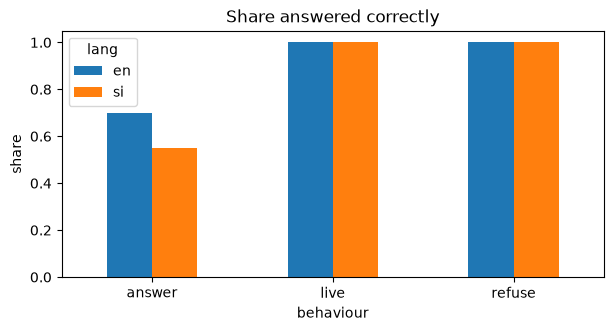

In [6]:
by = res.assign(correct=res.answer_ok.astype(str) == "True").groupby(["behaviour", "lang"]).correct.mean().unstack()
ax = by.plot.bar(figsize=(7, 3.2), rot=0, ylim=(0, 1.05), title="Share answered correctly")
ax.set_ylabel("share"); plt.show()

## Intent: expected vs predicted

In [7]:
pd.crosstab(res.expected_intent, res.intent)

intent,crop_choice,crop_establishment,deficiency_symptom,fertilizer_amount,liming_ph,my_field_status,out_of_scope,pest_disease,water_management,weeds
expected_intent,,,,,,,,,,
crop_choice,4,0,0,0,0,0,0,1,1,0
crop_establishment,0,12,0,0,0,0,0,0,1,0
fertilizer_amount,0,0,0,8,0,0,0,0,0,0
fertilizer_timing,0,0,0,0,0,2,0,0,0,0
liming_ph,0,0,0,0,1,2,0,0,0,0
my_field_status,0,0,0,0,0,6,0,0,0,0
out_of_scope,0,0,0,0,0,0,10,0,0,0
pest_disease,0,1,1,0,0,0,0,6,0,0
water_management,0,0,0,0,0,0,0,0,2,0


## What went wrong (document and live questions)

In [8]:
bad = res[(res.behaviour != "refuse") & (res.answer_ok.astype(str) != "True")]
print(f"{len(bad)} of {(res.behaviour != 'refuse').sum()} answerable questions not fully correct")
bad[["id", "lang", "expected_intent", "intent", "hit3", "path", "question", "answer"]].assign(answer=bad.answer.str.slice(0, 160))

15 of 50 answerable questions not fully correct


,id,lang,expected_intent,intent,hit3,path,question,answer
2,Q03,en,fertilizer_amount,fertilizer_amount,True,extractive+template,"In the Wet Zone without irrigation, how much MOP is recommended in total?",Age Group | Time * | Urea | T.S.P | M.O.P | Zinc Sulphate\nFor 3 1/2 Month | Basic | | 35 | |\nTotal | 140 | 35 | 50 | 5\nFor your field...
6,Q07,en,pest_disease,deficiency_symptom,True,extractive,Young plants are wilting - is it kresek or stem borer? How do I check?,The caterpillars bore into the rice stem and hollow out the stem completely.\nAttacked young plant shows dead heart and older plants sho...
8,Q09,en,weeds,weeds,True,extractive,During which weeks do weeds hurt my rice crop the most?,"Cause major direct/indirect economic losses in rice cultivation increased production costs.\nTherefore, considered to be major pests in ..."
11,Q12,en,crop_establishment,crop_establishment,False,extractive,How much seed paddy for a dry-bed nursery per hectare?,Requirement About 50 kg per Ha.
12,Q13,en,crop_establishment,crop_establishment,True,extractive,How many parachute trays are needed for a hectare?,"Generally 310 parachute trays are sufficient for seedling broadcasting in one acre but due to the field and environmental conditions, su..."
13,Q14,en,crop_choice,crop_choice,True,extractive,How many days until Bg 300 is ready to harvest?,"On crop basis, 30 days are needed to harvest after 80 percent heading of the crop."
23,Q24,si,fertilizer_amount,fertilizer_amount,True,extractive+template,පස් පරීක්ෂාවේ පොටෑසියම් 100ක් ආවා. එම්.ඕ.පී. කොච්චර දාන්නද?,පාංශු විශ්ලේෂක අගයයන් | අක්කර එකක් සදහා ටී. එස්. පී. හා එම්. ඕ. පී. ප්‍රමාණයන්\n5 -10 මි. ග්‍රෑම්/ කි. ග්‍රෑම් | 12 | |\n>10 මි. ග්‍රෑම්...
25,Q26,si,crop_choice,pest_disease,True,extractive,කොළ පාළුවට ඔරොත්තු දෙන වී වර්ග කියන්න.,හානියේ තරම හා බරපතලකම අනුව පහත සඳහන් කෘමීන් ශ්‍රී ලංකාවේ සහල් වල ප්‍රධාන පළිබෝධකයන් ලෙස සැලකේ
28,Q29,si,crop_establishment,crop_establishment,True,extractive,මඩ තවානකට හෙක්ටයාරයකට බිත්තර වී කීයක් ඕනද?,අවශ්‍යතාවය හෙක්ටයාරයකට කිලෝ 20-30 ක් පමණ මෙම ක්‍රමය මඟින් බීජ වී සඳහා ගොවියාට වන වියදම අඩු කරගත හැකිය.\nබීජ සකස් කිරීම පැය 24ක් පිරිසිදු...
32,Q33,si,crop_establishment,crop_establishment,True,extractive,පැල සිටවන්න ඕන කොච්චර ගැඹුරටද?,සීසෑමේ නිර්දේශිත ගැඹුර සෙන්ටිමීටර 20 ක් පමණ වේ.


## Refusals

In [9]:
res[res.behaviour == "refuse"][["id", "lang", "question", "intent", "path"]]

,id,lang,question,intent,path
50,Q51,en,Which party will win the provincial council election?,out_of_scope,refused
51,Q52,en,My son has a high fever. What medicine should I give him?,out_of_scope,refused
52,Q53,en,What is the best smartphone under 40000 rupees?,out_of_scope,refused
53,Q54,en,How do I prune my tea bushes in the hill country?,out_of_scope,refused
54,Q55,en,Can you write a birthday poem for my wife?,out_of_scope,refused
55,Q56,si,ලබන මැතිවරණයෙන් බලයට එන්නේ කවුද?,out_of_scope,refused
56,Q57,si,"මට හිසරදයක්, බොන්න ඕන පෙත්ත මොකක්ද?",out_of_scope,refused
57,Q58,si,හොඳ ලැප්ටොප් එකක් ගන්න කොච්චර යනවද?,out_of_scope,refused
58,Q59,si,පොල් ගස් වලට හොඳම පොහොර මොකක්ද?,out_of_scope,refused
59,Q60,si,ඊයේ ක්‍රිකට් තරගය දිනුවේ කවුද?,out_of_scope,refused


## Latency on CPU

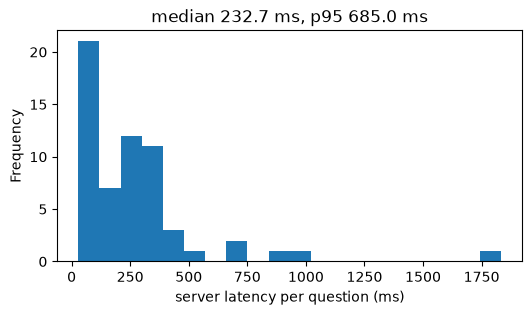

path
extractive             272.0
extractive+template    668.0
refused                 35.0
template                35.0
Name: latency_ms, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
res.latency_ms.astype(float).plot.hist(bins=20, ax=ax); ax.set_xlabel("server latency per question (ms)")
ax.set_title(f"median {metrics['overall']['latency_ms_median']} ms, p95 {metrics['overall']['latency_ms_p95']} ms"); plt.show()
res.groupby("path").latency_ms.median().round(0)

## How to read this
- **Document questions:** the answer counts as correct only if *every* key fact (number or term from the source
  passage) appears in it. Retrieval hit@3 counts the expected passage, or a passage of the same document or its
  other-language twin that contains all key facts.
- **Live questions:** correct if every live value named in `live_checks` (read from Member 2/3 APIs at run time)
  appears in the answer.
- **Hallucinated number:** a number in the answer that is in no cited passage and no live API value (rounding
  of a source number is allowed). Extractive answers copy text, so this should stay 0.
- The set is small (60); one question moves a language's score by 2–5 points.